In [1]:
import os, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

for d in ["figures", "gifs", "checkpoints", "tables"]:
    os.makedirs(d, exist_ok=True)

Device: cuda NVIDIA GeForce RTX 3060


Load and split the data

In [2]:
ds = torchvision.datasets.MovingMNIST(root="./data", split=None, download=True)
videos = torch.stack([ds[i] for i in range(len(ds))])   
print(videos.shape, videos.dtype)

# Split by video index (NOT the built-in train/test split)
train_videos = videos[:8000]
val_videos   = videos[8000:9000]
test_videos  = videos[9000:10000]

def to_float(x):
    return x.float() / 255.0   

torch.Size([10000, 20, 1, 64, 64]) torch.uint8


Pixels kept: 103050,  median speed: 3.318 px/frame  (2x ≈ 6.64, 3x ≈ 9.95)


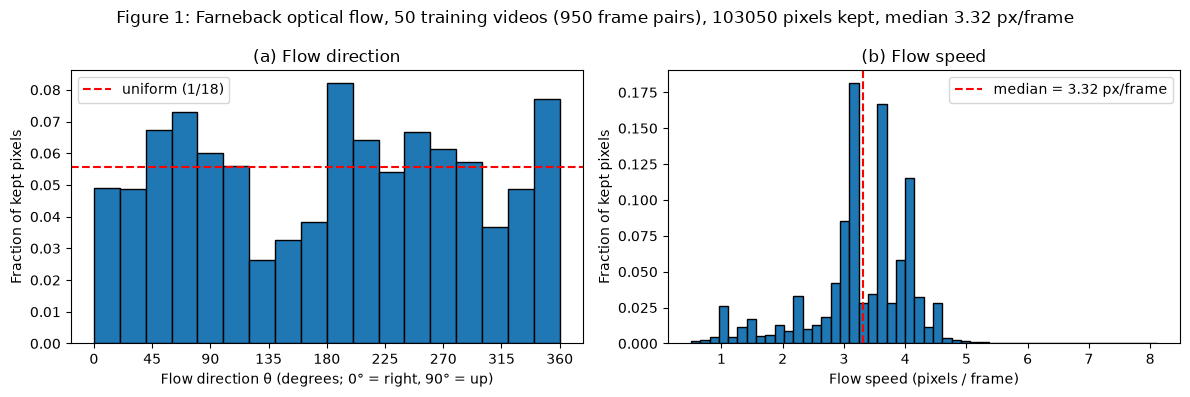

0-20°       0.0490
20-40°      0.0488
40-60°      0.0675
60-80°      0.0731
80-100°     0.0602
100-120°    0.0561
120-140°    0.0263
140-160°    0.0326
160-180°    0.0384
180-200°    0.0820
200-220°    0.0643
220-240°    0.0541
240-260°    0.0667
260-280°    0.0614
280-300°    0.0572
300-320°    0.0367
320-340°    0.0488
340-360°    0.0772
dtype: float32


In [26]:
import cv2

vids = train_videos[:50, :, 0].numpy()          # first 50 TRAINING videos, (50, 20, 64, 64) uint8
dirs, speeds = [], []
for v in vids:
    for s in range(19):                          # 19 pairs per video -> 950 pairs
        prev, nxt = v[s], v[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx**2 + dy**2)
        keep = (prev > 51) & (nxt > 51) & (mag > 0.5)    # intensity > 0.2 in both frames, flow > 0.5 px
        dirs.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360)
        speeds.append(mag[keep])

dirs, speeds = np.concatenate(dirs), np.concatenate(speeds)
n_kept, med = len(speeds), np.median(speeds)
print(f"Pixels kept: {n_kept},  median speed: {med:.3f} px/frame  (2x ≈ {2*med:.2f}, 3x ≈ {3*med:.2f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
w = np.ones_like(dirs) / n_kept
ax[0].hist(dirs, bins=np.arange(0, 361, 20), weights=w, edgecolor="k")
ax[0].axhline(1/18, color="r", ls="--", label="uniform (1/18)")
ax[0].set_xlabel("Flow direction θ (degrees; 0° = right, 90° = up)"); ax[0].set_ylabel("Fraction of kept pixels")
ax[0].set_xticks(range(0, 361, 45)); ax[0].set_title("(a) Flow direction"); ax[0].legend()
ax[1].hist(speeds, bins=50, weights=np.ones_like(speeds) / n_kept, edgecolor="k")
ax[1].axvline(med, color="r", ls="--", label=f"median = {med:.2f} px/frame")
ax[1].set_xlabel("Flow speed (pixels / frame)"); ax[1].set_ylabel("Fraction of kept pixels")
ax[1].set_title("(b) Flow speed"); ax[1].legend()
fig.suptitle(f"Figure 1: Farneback optical flow, 50 training videos (950 frame pairs), "
             f"{n_kept} pixels kept, median {med:.2f} px/frame")
plt.tight_layout(); plt.savefig("figures/figure1.png", dpi=150); plt.show()

counts, _ = np.histogram(dirs, bins=np.arange(0, 361, 20), weights=w)
print(pd.Series(counts.round(4), index=[f"{b}-{b+20}°" for b in range(0, 360, 20)]))

In [3]:
def mirror(x):                
    return x.flip(-1)

def rot(x, a=1):               
    return torch.rot90(x, k=a, dims=(-2, -1))

# Each element g = (m, a) means  g(x) = M(R^a(x)) if m else R^a(x)
G = [(m, a) for m in (0, 1) for a in range(4)]

def apply_g(g, x):
    m, a = g
    y = rot(x, a)
    return mirror(y) if m else y

def apply_g_inv(g, x):
    m, a = g
    return apply_g(g, x) if m else rot(x, -a)   

In [4]:
ALLOWED_STARTS_NORMAL = {1: list(range(1, 12))}                              # models A, B
ALLOWED_STARTS_AUG    = {1: list(range(1, 15)), 2: list(range(1, 9)), 3: [1, 2]}  # models C, D

def make_window(video, t, k=1):
    """video: (20, C, H, W) with frames numbered 1..20.
    Returns X (5,C,H,W), Y (5,C,H,W) zero-padded, mask (5,) bool for which targets exist."""
    in_idx  = [t + j * k for j in range(5)]
    tgt_idx = [t + (5 + j) * k for j in range(5)]
    assert in_idx[-1] <= 20, "input frame out of range"
    X = video[[i - 1 for i in in_idx]]
    valid = [i - 1 for i in tgt_idx if i <= 20]
    Y = torch.zeros_like(X)
    Y[:len(valid)] = video[valid]
    mask = torch.tensor([i <= 20 for i in tgt_idx])
    return X, Y, mask

In [5]:
torch.manual_seed(0); x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1

def maxdiff(a, b): return (a - b).abs().max().item()
def bright(v): return tuple(int(i) for i in (v == 1).nonzero()[0][[0, 2, 3]])  # (frame, row, col)

rows = []
a = mirror(mirror(x))
rows.append(("(a) max|M(M(x)) − x|", "0", f"{maxdiff(a, x)} (torch.equal={torch.equal(a, x)})"))
b = rot(x, 4)
rows.append(("(b) max|R^4(x) − x|", "0", f"{maxdiff(b, x)} (torch.equal={torch.equal(b, x)})"))
c1, c2 = mirror(rot(mirror(x), 1)), rot(x, -1)
rows.append(("(c) max|MRM(x) − R^-1(x)|", "0", f"{maxdiff(c1, c2)} (torch.equal={torch.equal(c1, c2)})"))
rows.append(("(d) bright pixel of M(p)", "(7, 10, 43)", str(bright(mirror(p)))))
rows.append(("(e) bright pixel of R(p)", "(7, 43, 10)", str(bright(rot(p, 1)))))

f_video = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64)
def frames_read(k):
    X, Y, mask = make_window(f_video, t=1, k=k)
    xin = [int(v) for v in X[:, 0, 0, 0]]
    yt  = [int(v) for v, m in zip(Y[:, 0, 0, 0], mask) if m]
    return f"{', '.join(map(str, xin))} / {', '.join(map(str, yt))}"

rows.append(("(f) 1× input / target", "1–5 / 6–10", frames_read(1)))
rows.append(("(g) 2× input / target", "1, 3, 5, 7, 9 / 11, 13, 15, 17, 19", frames_read(2)))
rows.append(("(h) 3× input / target", "1, 4, 7, 10, 13 / 16, 19", frames_read(3)))

table1 = pd.DataFrame(rows, columns=["Check", "Expected", "Yours"])
table1.to_csv("tables/table1.csv", index=False)
display(table1)

# Extra sanity check: every group element inverts exactly
for g in G:
    assert torch.equal(apply_g_inv(g, apply_g(g, x)), x), g
print("All 8 symmetries invert correctly.")

,Check,Expected,Yours
0,(a) max|M(M(x)) − x|,0,0.0 (torch.equal=True)
1,(b) max|R^4(x) − x|,0,0.0 (torch.equal=True)
2,(c) max|MRM(x) − R^-1(x)|,0,0.0 (torch.equal=True)
3,(d) bright pixel of M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) bright pixel of R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1× input / target,1–5 / 6–10,"1, 2, 3, 4, 5 / 6, 7, 8, 9, 10"
6,(g) 2× input / target,"1, 3, 5, 7, 9 / 11, 13, 15, 17, 19","1, 3, 5, 7, 9 / 11, 13, 15, 17, 19"
7,(h) 3× input / target,"1, 4, 7, 10, 13 / 16, 19","1, 4, 7, 10, 13 / 16, 19"


All 8 symmetries invert correctly.


In [6]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3, dilation=1):
        super().__init__()
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k,
                              padding=dilation * (k // 2), dilation=dilation)   # bias=True by default

    def forward(self, u, h, c):
        i, f, o, g = self.conv(torch.cat([u, h], 1)).chunk(4, 1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ConvLSTMForecaster(nn.Module):
    """Defaults = model A. Arguments are kept so model D can reuse this class later."""
    def __init__(self, patch=4, hid=64, k=3, dilations=(1, 1)):
        super().__init__()
        self.patch, self.hid = patch, hid
        in_ch = patch * patch
        self.l1 = ConvLSTMCell(in_ch, hid, k, dilations[0])
        self.l2 = ConvLSTMCell(hid, hid, k, dilations[1])
        self.out = nn.Conv2d(hid, in_ch, 1)

    def forward(self, X):                         # X: (B, 5, 1, 64, 64)
        B, s = X.shape[0], 64 // self.patch
        h1 = c1 = h2 = c2 = X.new_zeros(B, self.hid, s, s)
        outs, prev = [], None
        for tau in range(9):                      # steps 1..9
            inp = X[:, tau] if tau < 5 else prev  # steps 6..9 feed back own prediction (no teacher forcing)
            z = F.pixel_unshuffle(inp, self.patch)
            h1, c1 = self.l1(z, h1, c1)
            h2, c2 = self.l2(h1, h2, c2)
            prev = torch.sigmoid(F.pixel_shuffle(self.out(h2), self.patch))
            if tau >= 4:                          # outputs of steps 5..9 = Y_hat
                outs.append(prev)
        return torch.stack(outs, 1)               # (B, 5, 1, 64, 64)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print("Model A parameters:", n_params(ConvLSTMForecaster()), "(expected 480,784)")

Model A parameters: 480784 (expected 480,784)


In [7]:
def sample_batch(vids, idx, rng, aug_speed=False, aug_sym=False):
    Xs, Ys, Ms = [], [], []
    for i in idx:
        if aug_speed:
            k = int(rng.choice([1, 2, 3])); t = int(rng.choice(ALLOWED_STARTS_AUG[k]))
        else:
            k = 1; t = int(rng.choice(ALLOWED_STARTS_NORMAL[1]))
        X, Y, M = make_window(vids[i], t, k)
        if aug_sym:
            g = G[int(rng.integers(8))]           # same g for input and target
            X, Y = apply_g(g, X), apply_g(g, Y)
        Xs.append(X); Ys.append(Y); Ms.append(M)
    return to_float(torch.stack(Xs)), to_float(torch.stack(Ys)), torch.stack(Ms)

def masked_loss(pred, Y, M):
    se = ((pred - Y) ** 2).mean(dim=(2, 3, 4))          # (B, 5) per-horizon MSE
    per_video = (se * M).sum(1) / M.sum(1)              # average over available targets
    return per_video.mean()                             # then over videos

@torch.no_grad()
def predict(model, vids, k=1, t=1, g=None, bs=32):
    """Returns preds, targets, mask on CPU. If g is given, inputs AND targets are transformed by g."""
    model.eval(); P, T, Mk = [], [], []
    for b in range(0, len(vids), bs):
        Xs, Ys, Ms = zip(*[make_window(v, t, k) for v in vids[b:b + bs]])
        X, Y = to_float(torch.stack(Xs)), to_float(torch.stack(Ys))
        if g is not None:
            X, Y = apply_g(g, X), apply_g(g, Y)
        P.append(model(X.to(device)).cpu()); T.append(Y); Mk.append(torch.stack(Ms))
    return torch.cat(P), torch.cat(T), torch.cat(Mk)

def per_horizon_mse(P, Y):            # (N, 5): MSE_h per video
    return ((P - Y) ** 2).mean(dim=(2, 3, 4))

In [8]:
import json

def train_model(name, seed, model_kwargs=None, aug_speed=False, aug_sym=False, epochs=30, bs=32):
    set_seed(seed); rng = np.random.default_rng(seed)
    model = ConvLSTMForecaster(**(model_kwargs or {})).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    epoch_times = []
    for ep in range(epochs):
        model.train(); torch.cuda.synchronize(); t0 = time.time()
        perm = rng.permutation(len(train_videos)); total = 0.0
        for b in range(0, len(perm), bs):
            X, Y, M = sample_batch(train_videos, perm[b:b + bs], rng, aug_speed, aug_sym)
            X, Y, M = X.to(device), Y.to(device), M.to(device)
            loss = masked_loss(model(X), Y, M)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(X)
        torch.cuda.synchronize(); epoch_times.append(time.time() - t0)
        P, T, _ = predict(model, val_videos)               # validation monitoring only
        val_e5 = per_horizon_mse(P, T).mean().item()
        print(f"[{name} s{seed}] epoch {ep+1:2d}  train {total/len(perm):.5f}  "
              f"val E5 {val_e5:.5f}  ({epoch_times[-1]:.1f}s)")
    torch.save(model.state_dict(), f"checkpoints/{name}_seed{seed}.pt")
    info = {"name": name, "seed": seed, "params": n_params(model),
            "train_time_per_epoch_s": float(np.mean(epoch_times)), "model_kwargs": model_kwargs or {}}
    json.dump(info, open(f"checkpoints/{name}_seed{seed}.json", "w"))
    return model, info

In [9]:
for seed in [0, 1]:
    train_model("A", seed)

[A s0] epoch  1  train 0.04610  val E5 0.03932  (14.9s)
[A s0] epoch  2  train 0.03968  val E5 0.03858  (14.5s)
[A s0] epoch  3  train 0.03868  val E5 0.03735  (14.6s)
[A s0] epoch  4  train 0.03712  val E5 0.03588  (15.1s)
[A s0] epoch  5  train 0.03537  val E5 0.03402  (14.9s)
[A s0] epoch  6  train 0.03373  val E5 0.03227  (14.5s)
[A s0] epoch  7  train 0.03236  val E5 0.03175  (14.6s)
[A s0] epoch  8  train 0.03139  val E5 0.03036  (14.6s)
[A s0] epoch  9  train 0.03055  val E5 0.02990  (14.8s)
[A s0] epoch 10  train 0.02986  val E5 0.02927  (14.5s)
[A s0] epoch 11  train 0.02936  val E5 0.02890  (14.6s)
[A s0] epoch 12  train 0.02883  val E5 0.02820  (14.4s)
[A s0] epoch 13  train 0.02832  val E5 0.02783  (14.6s)
[A s0] epoch 14  train 0.02786  val E5 0.02731  (14.9s)
[A s0] epoch 15  train 0.02746  val E5 0.02695  (14.9s)
[A s0] epoch 16  train 0.02708  val E5 0.02667  (14.9s)
[A s0] epoch 17  train 0.02669  val E5 0.02670  (14.8s)
[A s0] epoch 18  train 0.02638  val E5 0.02590  

In [10]:
import imageio.v3 as iio

models_A = {}
for s in [0, 1]:
    m = ConvLSTMForecaster().to(device)
    m.load_state_dict(torch.load(f"checkpoints/A_seed{s}.pt", map_location=device)); m.eval()
    models_A[s] = m

class Blank(nn.Module):
    def forward(self, X): return torch.zeros_like(X)
class CopyLast(nn.Module):
    def forward(self, X): return X[:, -1:].expand_as(X).clone()
blank, copylast = Blank().to(device), CopyLast().to(device)

def fmt(v):                       # 3 significant figures, scientific below 1e-3
    return f"{v:.2e}" if v != 0 and abs(v) < 1e-3 else f"{v:.3g}"
def fmt_seeds(vals):              # "mean (seed 0, seed 1)"
    return f"{fmt(float(np.mean(vals)))} ({fmt(vals[0])}, {fmt(vals[1])})"

def show_grid(rows, row_labels, title, path):
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(1.25 * nc, 1.3 * nr), squeeze=False)
    for i, r in enumerate(rows):
        for j in range(nc):
            ax = axes[i, j]; ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_visible(False)
            if j < len(r): ax.imshow(r[j].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[i, 0].set_ylabel(row_labels[i], rotation=0, ha="right", va="center", fontsize=8)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()

def bright_counts(v):             # bright-pixel count per frame (uint8 video)
    return (v[:, 0] > 51).flatten(1).sum(1).float()
def overlap_score(v, frames):     # lower = digits more likely overlapping in these frames
    c = bright_counts(v); return (c[[f - 1 for f in frames]].min() / c.median()).item()

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),Params
0,Model A,"0.0166 (0.017, 0.0162)","0.0203 (0.0207, 0.0199)","0.0226 (0.0231, 0.0222)","0.0244 (0.0249, 0.024)","0.0262 (0.0267, 0.0257)","0.022 (0.0225, 0.0216)",480784
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


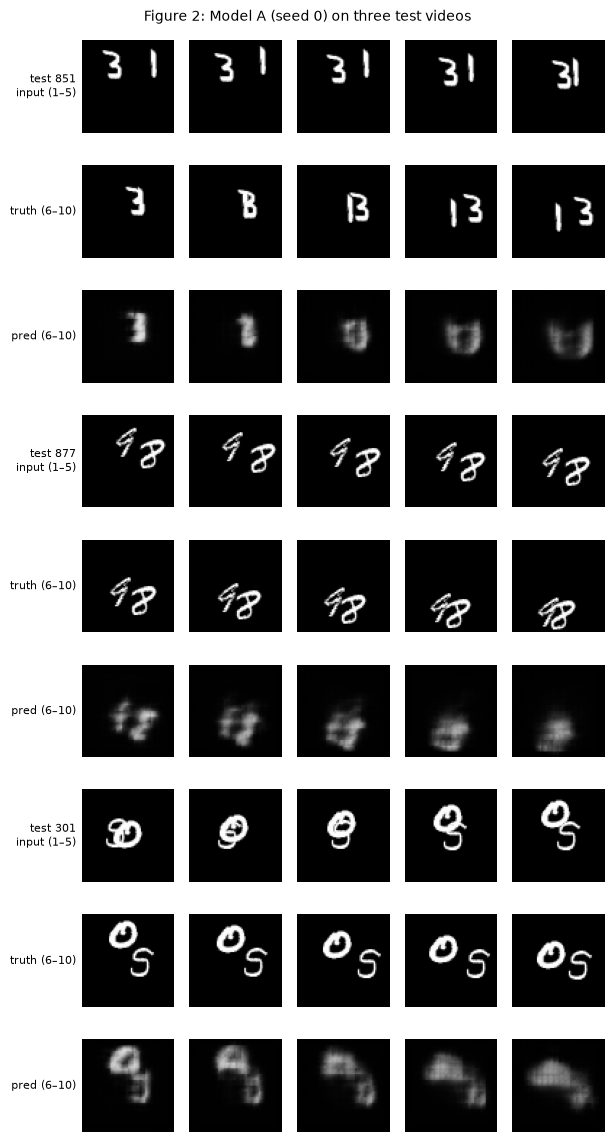

Figure 2 videos: [851, 877, 301] (first should show overlapping digits)


In [11]:
def horizon_mse(model, k=1):
    P, Y, _ = predict(model, test_videos, k=k)
    return per_horizon_mse(P, Y)                     # (1000, 5)

mse_A = {s: horizon_mse(models_A[s]) for s in [0, 1]}
mse_blank, mse_copy = horizon_mse(blank), horizon_mse(copylast)

cols = [f"MSE{h}" for h in range(1, 6)] + ["E(5)", "Params"]
rows = [["Model A"] + [fmt_seeds([mse_A[s][:, h].mean().item() for s in [0, 1]]) for h in range(5)]
        + [fmt_seeds([mse_A[s].mean().item() for s in [0, 1]]), n_params(models_A[0])]]
for name, m in [("Blank", mse_blank), ("Copy-last", mse_copy)]:
    rows.append([name] + [fmt(m[:, h].mean().item()) for h in range(5)] + [fmt(m.mean().item()), 0])
table2 = pd.DataFrame(rows, columns=["Model"] + cols)
table2.to_csv("tables/table2.csv", index=False); display(table2)

# Figure 2: one overlapping-digit video + two clean ones (verify visually!)
scores = np.array([overlap_score(v, range(6, 11)) for v in test_videos])
fig2_idx = [int(scores.argmin()), *map(int, np.argsort(scores)[-2:])]
P, Y, _ = predict(models_A[0], test_videos[fig2_idx])
X = to_float(test_videos[fig2_idx][:, :5])
rows, labels = [], []
for i, vid in enumerate(fig2_idx):
    rows += [list(X[i]), list(Y[i]), list(P[i])]
    labels += [f"test {vid}\ninput (1–5)", "truth (6–10)", "pred (6–10)"]
show_grid(rows, labels, "Figure 2: Model A (seed 0) on three test videos", "figures/figure2.png")
print("Figure 2 videos:", fig2_idx, "(first should show overlapping digits)")

In [12]:
TRANSFORMS = {"M": (1, 0), "R": (0, 1)}

def consistency(model):
    P, Y, _ = predict(model, test_videos)
    out = {"E5": per_horizon_mse(P, Y).mean(1)}                     # per-video values
    for name, g in TRANSFORMS.items():
        PT, YT, _ = predict(model, test_videos, g=g)                # f(T(X)), T(Y)
        out["C" + name] = ((PT - apply_g(g, P)) ** 2).mean(dim=(1, 2, 3, 4))
        out["E" + name] = ((PT - YT) ** 2).mean(dim=(1, 2, 3, 4))
    return out

res3 = {s: consistency(models_A[s]) for s in [0, 1]}
res3_blank, res3_copy = consistency(blank), consistency(copylast)

c3 = ["E5", "CM", "EM", "CR", "ER"]
rows = [["Model A"] + [fmt_seeds([res3[s][c].mean().item() for s in [0, 1]]) for c in c3]]
rows += [[n] + [fmt(r[c].mean().item()) for c in c3] for n, r in [("Blank", res3_blank), ("Copy-last", res3_copy)]]
table3 = pd.DataFrame(rows, columns=["Model", "E(5)", "C_M", "E_M", "C_R", "E_R"])
table3.to_csv("tables/table3.csv", index=False); display(table3)

,Model,E(5),C_M,E_M,C_R,E_R
0,Model A,"0.022 (0.0225, 0.0216)","0.00182 (0.00177, 0.00187)","0.0227 (0.0232, 0.0223)","0.00295 (0.00294, 0.00296)","0.0237 (0.0242, 0.0233)"
1,Blank,0.0426,0,0.0426,0,0.0426
2,Copy-last,0.0641,0,0.0641,0,0.0641


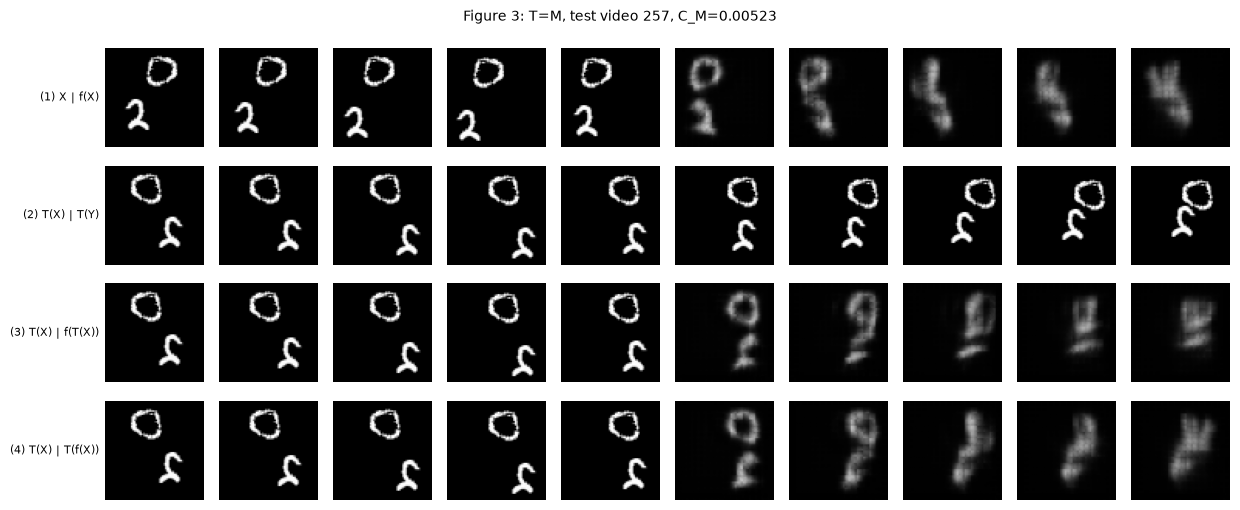

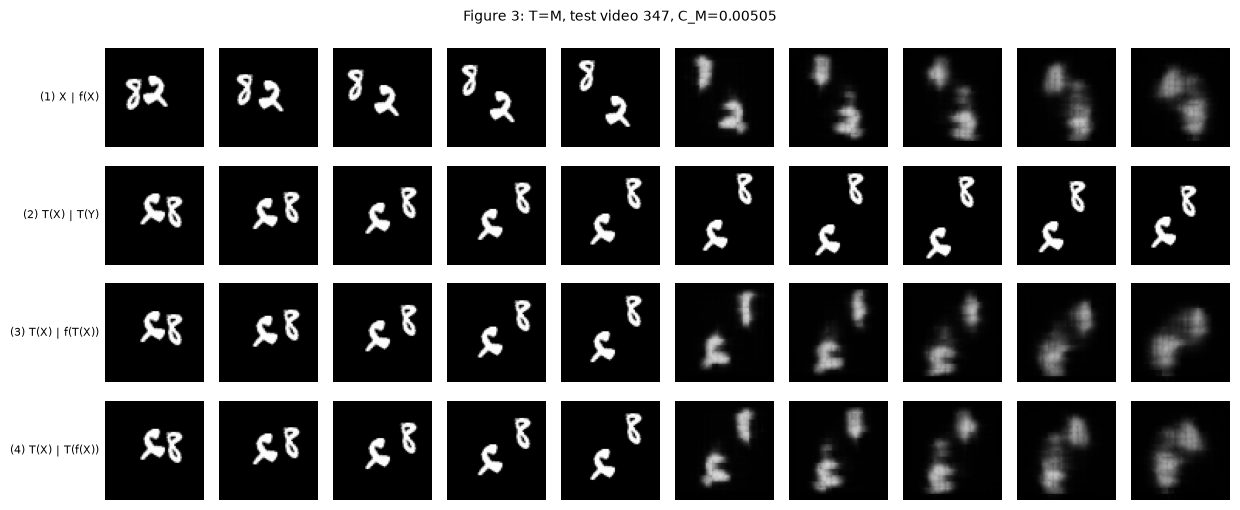

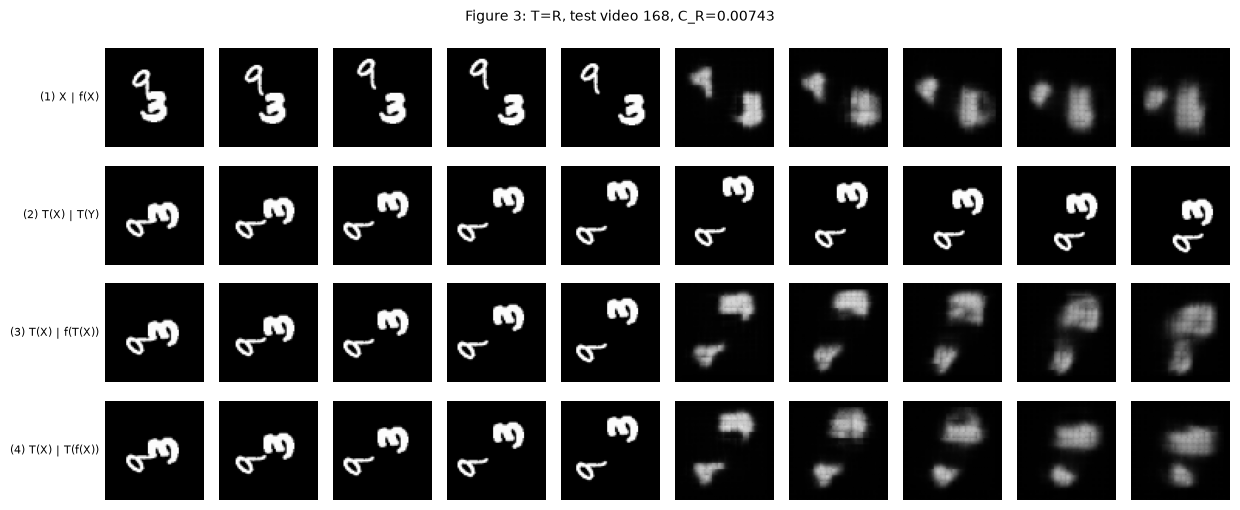

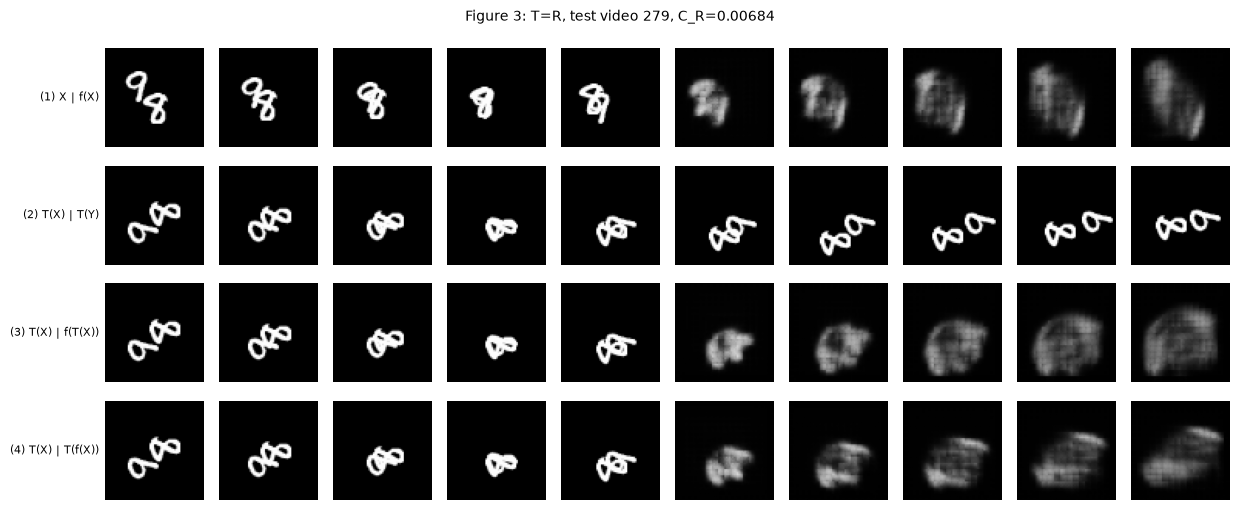

Figure 3 videos: {'CM': [257, 347], 'CR': [168, 279]} 
GIFs: ['gifs/figure3_A_M_test257.gif', 'gifs/figure3_A_M_test347.gif', 'gifs/figure3_A_R_test168.gif', 'gifs/figure3_A_R_test279.gif']


In [13]:
@torch.no_grad()
def four_rows(model, v, g):
    X, Y, _ = make_window(v, 1, 1); X, Y = to_float(X)[None], to_float(Y)[None]
    fX = model(X.to(device)).cpu(); TX = apply_g(g, X); fTX = model(TX.to(device)).cpu()
    return [list(X[0]) + list(fX[0]),            # (1) X | f(X)
            list(TX[0]) + list(apply_g(g, Y)[0]),# (2) T(X) | T(Y)
            list(TX[0]) + list(fTX[0]),          # (3) T(X) | f(T(X))
            list(TX[0]) + list(apply_g(g, fX)[0])]  # (4) T(X) | T(f(X))

def save_gif(rows, path, scale=3):
    frames = []
    for h in range(5):                           # each frame: last input | horizon-h frame, for all 4 rows
        tiles = []
        for r in rows:
            tiles += [np.concatenate([r[4][0].numpy(), np.ones((64, 2)), r[5 + h][0].numpy()], 1), np.ones((2, 130))]
        img = np.kron(np.concatenate(tiles[:-1], 0), np.ones((scale, scale)))
        frames.append((img * 255).clip(0, 255).astype(np.uint8))
    iio.imwrite(path, np.stack(frames), duration=700, loop=0)

fig3_idx = {c: torch.topk(res3[0][c], 2).indices.tolist() for c in ["CM", "CR"]}
labels4 = ["(1) X | f(X)", "(2) T(X) | T(Y)", "(3) T(X) | f(T(X))", "(4) T(X) | T(f(X))"]
gif_paths = []
for c, tname in [("CM", "M"), ("CR", "R")]:
    for vid in fig3_idx[c]:
        rows = four_rows(models_A[0], test_videos[vid], TRANSFORMS[tname])
        path = f"figures/figure3_{tname}_test{vid}.png"
        show_grid(rows, labels4, f"Figure 3: T={tname}, test video {vid}, C_{tname}={res3[0][c][vid]:.3g}", path)
        gp = f"gifs/figure3_A_{tname}_test{vid}.gif"; save_gif(rows, gp); gif_paths.append(gp)
print("Figure 3 videos:", fig3_idx, "\nGIFs:", gif_paths)

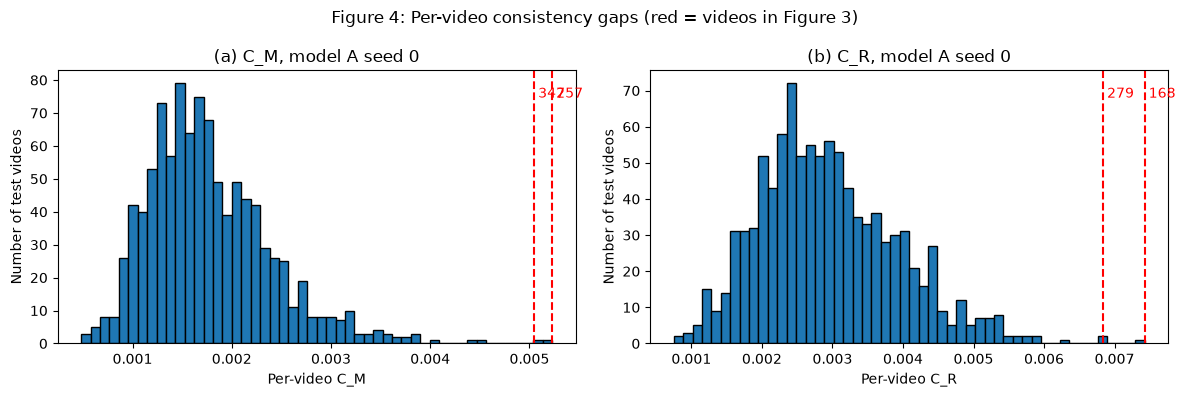

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, c in zip(ax, ["CM", "CR"]):
    vals = res3[0][c].numpy()
    a.hist(vals, bins=50, edgecolor="k")
    for vid in fig3_idx[c]:
        a.axvline(vals[vid], color="r", ls="--"); a.text(vals[vid], a.get_ylim()[1] * 0.9, f" {vid}", color="r")
    a.set_xlabel(f"Per-video {c[0]}_{c[1]}"); a.set_ylabel("Number of test videos")
    a.set_title(f"({'a' if c == 'CM' else 'b'}) {c[0]}_{c[1]}, model A seed 0")
fig.suptitle("Figure 4: Per-video consistency gaps (red = videos in Figure 3)")
plt.tight_layout(); plt.savefig("figures/figure4.png", dpi=150); plt.show()

,Model,E(2) 1×,E(2) 2×,E(2) 3×,E(5) 1×,E(5) 2×
0,Model A,"0.0185 (0.0188, 0.0181)","0.0457 (0.0448, 0.0466)","0.0533 (0.0523, 0.0542)","0.022 (0.0225, 0.0216)","0.0501 (0.0493, 0.051)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


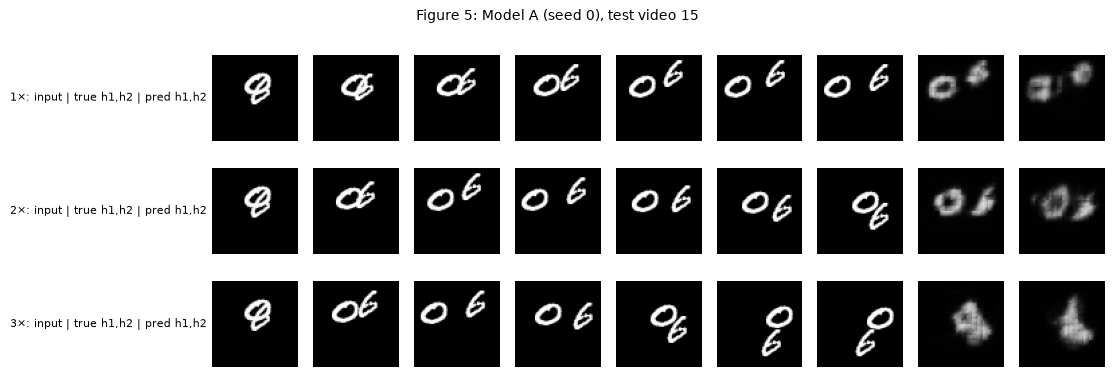

Figure 5 video: 15


In [15]:
def speed_err(model, k):
    mse = horizon_mse(model, k)
    return mse[:, :2].mean().item(), (mse.mean().item() if k < 3 else None)

sA = {s: {k: speed_err(models_A[s], k) for k in [1, 2, 3]} for s in [0, 1]}
sC = {k: speed_err(copylast, k) for k in [1, 2, 3]}
rows = [["Model A"] + [fmt_seeds([sA[s][k][0] for s in [0, 1]]) for k in [1, 2, 3]]
        + [fmt_seeds([sA[s][k][1] for s in [0, 1]]) for k in [1, 2]],
        ["Copy-last"] + [fmt(sC[k][0]) for k in [1, 2, 3]] + [fmt(sC[k][1]) for k in [1, 2]]]
table4 = pd.DataFrame(rows, columns=["Model", "E(2) 1×", "E(2) 2×", "E(2) 3×", "E(5) 1×", "E(5) 2×"])
table4.to_csv("tables/table4.csv", index=False); display(table4)

# Figure 5: video with no overlap in the displayed true frames
shown = [6, 7, 11, 13, 16, 19]
fig5_vid = int(np.argmax([overlap_score(v, shown) for v in test_videos]))
rows, labels = [], []
for k in [1, 2, 3]:
    P, Y, _ = predict(models_A[0], test_videos[fig5_vid:fig5_vid + 1], k=k)
    X, _, _ = make_window(test_videos[fig5_vid], 1, k)
    rows.append(list(to_float(X)) + list(Y[0, :2]) + list(P[0, :2]))
    labels.append(f"{k}×: input | true h1,h2 | pred h1,h2")
show_grid(rows, labels, f"Figure 5: Model A (seed 0), test video {fig5_vid}", "figures/figure5.png")
print("Figure 5 video:", fig5_vid)

,Model,E(2) 1×,E(2) 2×,E(2) 3×,E(5) 1×,E(5) 2×
0,Model A,"0.0185 (0.0188, 0.0181)","0.0457 (0.0448, 0.0466)","0.0533 (0.0523, 0.0542)","0.022 (0.0225, 0.0216)","0.0501 (0.0493, 0.051)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


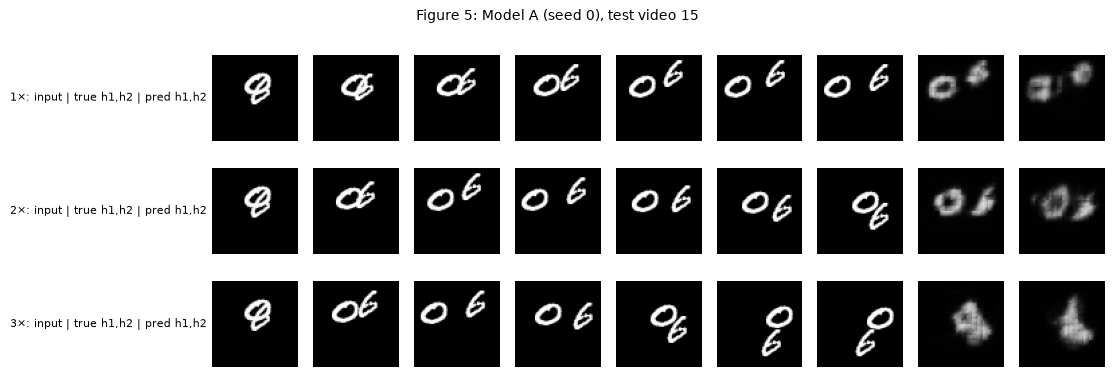

Figure 5 video: 15


In [ ]:
def speed_err(model, k):
    mse = horizon_mse(model, k)
    return mse[:, :2].mean().item(), (mse.mean().item() if k < 3 else None)

sA = {s: {k: speed_err(models_A[s], k) for k in [1, 2, 3]} for s in [0, 1]}
sC = {k: speed_err(copylast, k) for k in [1, 2, 3]}
rows = [["Model A"] + [fmt_seeds([sA[s][k][0] for s in [0, 1]]) for k in [1, 2, 3]]
        + [fmt_seeds([sA[s][k][1] for s in [0, 1]]) for k in [1, 2]],
        ["Copy-last"] + [fmt(sC[k][0]) for k in [1, 2, 3]] + [fmt(sC[k][1]) for k in [1, 2]]]
table4 = pd.DataFrame(rows, columns=["Model", "E(2) 1×", "E(2) 2×", "E(2) 3×", "E(5) 1×", "E(5) 2×"])
table4.to_csv("tables/table4.csv", index=False); display(table4)

# Figure 5: video whose two digits are clearly separate in every displayed frame
from scipy import ndimage
def two_blobs(v, frames):
    return all(ndimage.label(v[f-1, 0].numpy() > 51)[1] == 2 for f in frames)
cands = [i for i, v in enumerate(test_videos)
         if two_blobs(v, [1,2,3,4,5, 1,3,5,7,9, 1,4,7,10,13, 6,7, 11,13, 16,19])]
print(len(cands), cands[:10])
fig5_vid = cands[0]

rows, labels = [], []
for k in [1, 2, 3]:
    P, Y, _ = predict(models_A[0], test_videos[fig5_vid:fig5_vid + 1], k=k)
    X, _, _ = make_window(test_videos[fig5_vid], 1, k)
    rows.append(list(to_float(X)) + list(Y[0, :2]) + list(P[0, :2]))
    labels.append(f"{k}×: input | true h1,h2 | pred h1,h2")
show_grid(rows, labels, f"Figure 5: Model A (seed 0), test video {fig5_vid}", "figures/figure5.png")
print("Figure 5 video:", fig5_vid)

In [17]:
def empirical_reach(model_kwargs=None):
    """Feed an impulse in the input at one cell and measure, in cells and px,
    how far the one-step prediction depends on it (zero initial state)."""
    m = ConvLSTMForecaster(**(model_kwargs or {})).to(device).eval()
    x = torch.zeros(1, 1, 64, 64, device=device, requires_grad=True)
    z = F.pixel_unshuffle(x, m.patch); h = z.new_zeros(1, m.hid, 16, 16)
    h1, c1 = m.l1(z, h, h); h2, _ = m.l2(h1, h, h)
    out = F.pixel_unshuffle(torch.sigmoid(F.pixel_shuffle(m.out(h2), m.patch)), m.patch)
    out[0, :, 8, 8].sum().backward()                       # one output cell at the centre
    g = F.pixel_unshuffle(x.grad.abs(), m.patch).sum(1)[0] > 0
    rows, cols = torch.nonzero(g, as_tuple=True)
    r = int(max((rows - 8).abs().max(), (cols - 8).abs().max()))
    holes = int((~g[8 - r:9 + r, 8 - r:9 + r]).sum())
    return r, 4 * r, holes

for name, kw in [("A", None), ("D", {"dilations": (1, 3)})]:
    r, px, holes = empirical_reach(kw)
    print(f"Model {name}: reach = {r} cells = {px} px/step, unreachable cells inside: {holes}, "
          f"params = {n_params(ConvLSTMForecaster(**(kw or {})))}")

Model A: reach = 2 cells = 8 px/step, unreachable cells inside: 0, params = 480784
Model D: reach = 4 cells = 16 px/step, unreachable cells inside: 0, params = 480784


In [18]:
MODEL_SPECS = {
    "A": dict(model_kwargs=None,                 aug_speed=False, aug_sym=False),
    "B": dict(model_kwargs=None,                 aug_speed=False, aug_sym=True),
    "C": dict(model_kwargs=None,                 aug_speed=True,  aug_sym=False),
    "D": dict(model_kwargs={"dilations": (1, 3)}, aug_speed=True, aug_sym=False),
}
for name in ["B", "C", "D"]:
    for seed in [0, 1]:
        train_model(name, seed, **MODEL_SPECS[name])

[B s0] epoch  1  train 0.04608  val E5 0.03932  (16.1s)
[B s0] epoch  2  train 0.03967  val E5 0.03856  (16.7s)
[B s0] epoch  3  train 0.03871  val E5 0.03735  (16.3s)
[B s0] epoch  4  train 0.03729  val E5 0.03564  (15.4s)
[B s0] epoch  5  train 0.03545  val E5 0.03388  (15.8s)
[B s0] epoch  6  train 0.03374  val E5 0.03235  (15.4s)
[B s0] epoch  7  train 0.03223  val E5 0.03114  (15.8s)
[B s0] epoch  8  train 0.03133  val E5 0.03094  (16.0s)
[B s0] epoch  9  train 0.03051  val E5 0.02973  (15.8s)
[B s0] epoch 10  train 0.02988  val E5 0.02957  (16.0s)
[B s0] epoch 11  train 0.02938  val E5 0.02900  (15.9s)
[B s0] epoch 12  train 0.02899  val E5 0.02888  (15.3s)
[B s0] epoch 13  train 0.02870  val E5 0.02818  (15.9s)
[B s0] epoch 14  train 0.02818  val E5 0.02903  (15.6s)
[B s0] epoch 15  train 0.02788  val E5 0.02745  (15.4s)
[B s0] epoch 16  train 0.02743  val E5 0.02707  (16.1s)
[B s0] epoch 17  train 0.02707  val E5 0.02679  (16.0s)
[B s0] epoch 18  train 0.02673  val E5 0.02643  

In [19]:
def load_model(name, seed):
    m = ConvLSTMForecaster(**(MODEL_SPECS[name]["model_kwargs"] or {})).to(device)
    m.load_state_dict(torch.load(f"checkpoints/{name}_seed{seed}.pt", map_location=device))
    return m.eval()

models = {n: {s: load_model(n, s) for s in [0, 1]} for n in "ABCD"}

@torch.no_grad()
def inference_time(f, bs=32):
    """Wall-clock time to predict all 1000 test videos (1x, t=1), timing starts after each batch is on device."""
    batches = [to_float(torch.stack([make_window(v, 1, 1)[0] for v in test_videos[b:b + bs]]))
               for b in range(0, len(test_videos), bs)]
    if isinstance(f, nn.Module): f.eval()
    total = 0.0
    f(batches[0].to(device)); torch.cuda.synchronize()          # warm-up (not counted)
    for X in batches:
        X = X.to(device); torch.cuda.synchronize(); t0 = time.time()
        f(X); torch.cuda.synchronize(); total += time.time() - t0
    return total

def evaluate_row(name, fs, train_times):
    """fs: {seed: forecaster}. Returns one table row with mean (seed0, seed1) for every column."""
    cons = {s: consistency(fs[s]) for s in fs}
    spd  = {s: {k: speed_err(fs[s], k) for k in [1, 2, 3]} for s in fs}
    col = lambda vals: fmt_seeds(vals)
    return [name,
            col([cons[s]["E5"].mean().item() for s in fs]),
            col([cons[s]["CM"].mean().item() for s in fs]), col([cons[s]["EM"].mean().item() for s in fs]),
            col([cons[s]["CR"].mean().item() for s in fs]), col([cons[s]["ER"].mean().item() for s in fs]),
            col([spd[s][1][0] for s in fs]), col([spd[s][2][0] for s in fs]), col([spd[s][3][0] for s in fs]),
            n_params(fs[0]) if isinstance(fs[0], nn.Module) else n_params(fs[0].base),
            col(train_times),
            col([inference_time(fs[s]) for s in fs])]

COLS5 = ["Model", "E(5) 1×", "C_M", "E_M", "C_R", "E_R", "E(2) 1×", "E(2) 2×", "E(2) 3×",
         "Params", "Train s/epoch", "Inference s"]
train_t = lambda n: [json.load(open(f"checkpoints/{n}_seed{s}.json"))["train_time_per_epoch_s"] for s in [0, 1]]

table5 = pd.DataFrame([evaluate_row(n, models[n], train_t(n)) for n in "ABCD"], columns=COLS5)
table5.to_csv("tables/table5.csv", index=False)
pd.set_option("display.width", 250); display(table5)
print("Hardware:", torch.cuda.get_device_name(0))

,Model,E(5) 1×,C_M,E_M,C_R,E_R,E(2) 1×,E(2) 2×,E(2) 3×,Params,Train s/epoch,Inference s
0,A,"0.022 (0.0225, 0.0216)","0.00182 (0.00177, 0.00187)","0.0227 (0.0232, 0.0223)","0.00295 (0.00294, 0.00296)","0.0237 (0.0242, 0.0233)","0.0185 (0.0188, 0.0181)","0.0457 (0.0448, 0.0466)","0.0533 (0.0523, 0.0542)",480784,"14.8 (14.8, 14.9)","0.376 (0.376, 0.375)"
1,B,"0.0227 (0.0234, 0.0219)","0.00108 (9.38e-04, 0.00122)","0.0226 (0.0233, 0.0218)","0.00144 (0.00122, 0.00166)","0.0227 (0.0235, 0.0218)","0.0188 (0.0194, 0.0182)","0.0438 (0.0421, 0.0456)","0.0494 (0.0465, 0.0524)",480784,"15.9 (15.8, 15.9)","0.374 (0.375, 0.373)"
2,C,"0.0266 (0.0269, 0.0263)","0.00103 (9.08e-04, 0.00116)","0.0268 (0.0271, 0.0265)","0.00212 (0.00187, 0.00237)","0.0278 (0.0279, 0.0276)","0.023 (0.023, 0.0231)","0.029 (0.0292, 0.0287)","0.0335 (0.0335, 0.0335)",480784,"15 (14.9, 15)","0.373 (0.374, 0.373)"
3,D,"0.03 (0.0301, 0.03)","4.44e-04 (3.88e-04, 4.99e-04)","0.0301 (0.0301, 0.03)","8.60e-04 (6.62e-04, 0.00106)","0.0304 (0.0305, 0.0304)","0.0276 (0.0279, 0.0274)","0.0308 (0.0309, 0.0307)","0.0339 (0.0336, 0.0341)",480784,"15 (15, 15)","0.369 (0.369, 0.37)"


Hardware: NVIDIA GeForce RTX 3060


In [20]:
MODEL_SPECS["DB"] = dict(model_kwargs={"dilations": (1, 3)}, aug_speed=True, aug_sym=True)
for seed in [0, 1]:
    train_model("DB", seed, **MODEL_SPECS["DB"])
models["DB"] = {s: load_model("DB", s) for s in [0, 1]}

[DB s0] epoch  1  train 0.04642  val E5 0.03900  (16.4s)
[DB s0] epoch  2  train 0.03947  val E5 0.03852  (16.9s)
[DB s0] epoch  3  train 0.03901  val E5 0.03814  (16.4s)
[DB s0] epoch  4  train 0.03868  val E5 0.03786  (16.7s)
[DB s0] epoch  5  train 0.03827  val E5 0.03703  (15.9s)
[DB s0] epoch  6  train 0.03754  val E5 0.03620  (15.9s)
[DB s0] epoch  7  train 0.03702  val E5 0.03569  (16.2s)
[DB s0] epoch  8  train 0.03667  val E5 0.03557  (17.0s)
[DB s0] epoch  9  train 0.03629  val E5 0.03461  (16.4s)
[DB s0] epoch 10  train 0.03602  val E5 0.03594  (16.2s)
[DB s0] epoch 11  train 0.03581  val E5 0.03400  (15.8s)
[DB s0] epoch 12  train 0.03556  val E5 0.03439  (16.0s)
[DB s0] epoch 13  train 0.03530  val E5 0.03370  (15.8s)
[DB s0] epoch 14  train 0.03488  val E5 0.03297  (15.7s)
[DB s0] epoch 15  train 0.03470  val E5 0.03249  (16.0s)
[DB s0] epoch 16  train 0.03450  val E5 0.03214  (16.9s)
[DB s0] epoch 17  train 0.03431  val E5 0.03265  (16.9s)
[DB s0] epoch 18  train 0.03406

In [21]:
class Symmetrised(nn.Module):
    """f_bar(X) = 1/8 * sum_g g^{-1}( f(g(X)) )"""
    def __init__(self, base):
        super().__init__(); self.base = base
    def forward(self, X):
        return torch.stack([apply_g_inv(g, self.base(apply_g(g, X))) for g in G]).mean(0)

sym = {n: {s: Symmetrised(models[n][s]).eval() for s in [0, 1]} for n in ["B", "D", "DB"]}

# Choice of final model on VALIDATION only
for n in ["D", "DB"]:
    vals = []
    for s in [0, 1]:
        P, Y, _ = predict(sym[n][s], val_videos)
        vals.append(per_horizon_mse(P, Y).mean().item())
    print(f"Symmetrised {n}: val E(5) 1x = {fmt_seeds(vals)}")

Symmetrised D: val E(5) 1x = 0.0297 (0.0298, 0.0295)
Symmetrised DB: val E(5) 1x = 0.0298 (0.0302, 0.0294)


In [24]:
FINAL = "D"   # <- set from the validation result above
rows6 = [evaluate_row(f"Sym {n}", sym[n], train_t(n)) for n in ["B", "D"] + (["DB"] if FINAL == "DB" else [])]
table6 = pd.DataFrame(rows6, columns=COLS5)
table6.to_csv("tables/table6.csv", index=False); display(table6)
print("Final model: symmetrised", FINAL)

,Model,E(5) 1×,C_M,E_M,C_R,E_R,E(2) 1×,E(2) 2×,E(2) 3×,Params,Train s/epoch,Inference s
0,Sym B,"0.0221 (0.0229, 0.0212)","4.17e-17 (3.55e-17, 4.79e-17)","0.0221 (0.0229, 0.0212)","4.28e-17 (3.63e-17, 4.92e-17)","0.0221 (0.0229, 0.0212)","0.0184 (0.019, 0.0177)","0.0429 (0.0414, 0.0445)","0.0482 (0.0456, 0.0509)",480784,"15.9 (15.8, 15.9)","2.96 (2.96, 2.96)"
1,Sym D,"0.0299 (0.03, 0.0298)","2.56e-17 (2.30e-17, 2.81e-17)","0.0299 (0.03, 0.0298)","2.62e-17 (2.37e-17, 2.88e-17)","0.0299 (0.03, 0.0298)","0.0276 (0.0279, 0.0274)","0.0308 (0.0309, 0.0306)","0.0338 (0.0336, 0.034)",480784,"15 (15, 15)","2.93 (2.93, 2.93)"


Final model: symmetrised D


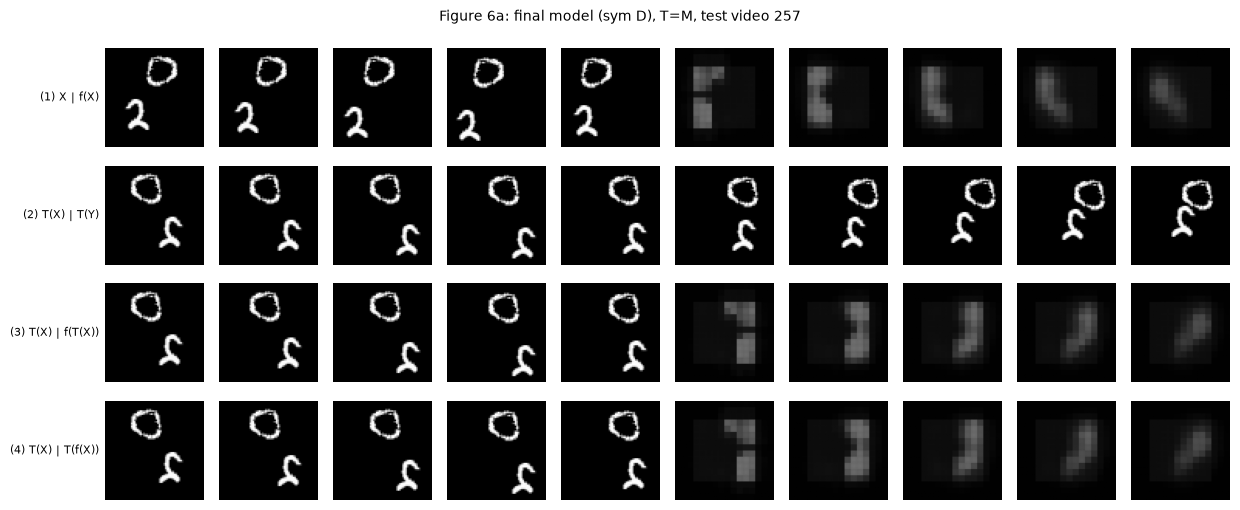

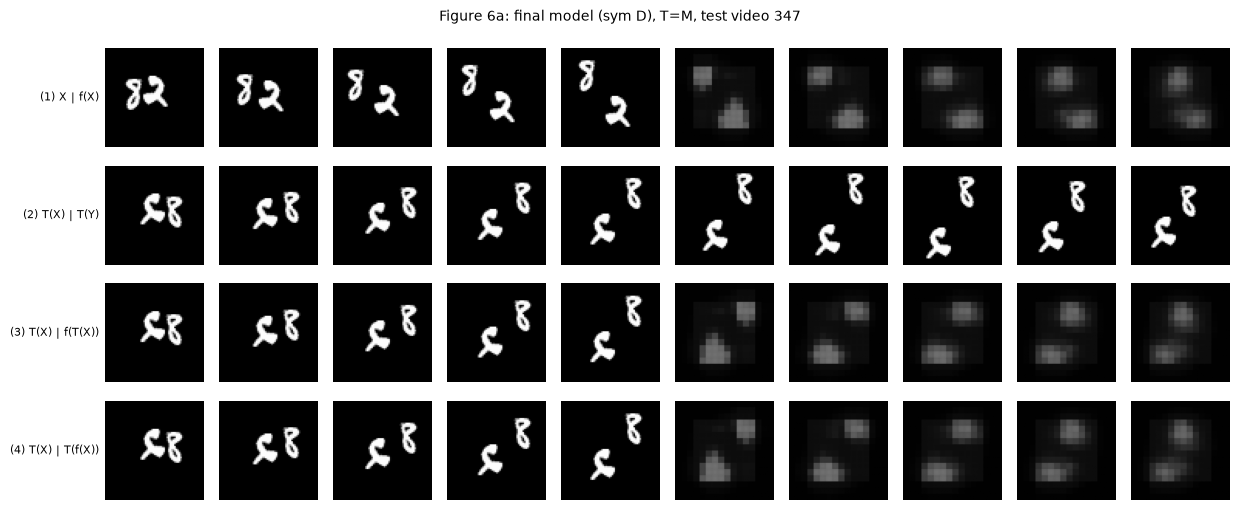

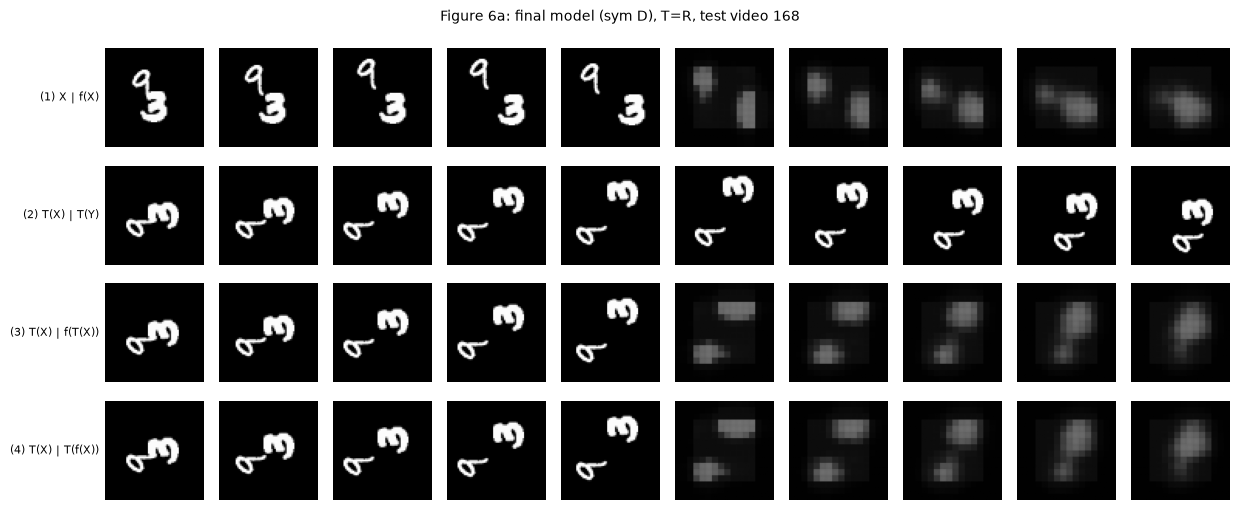

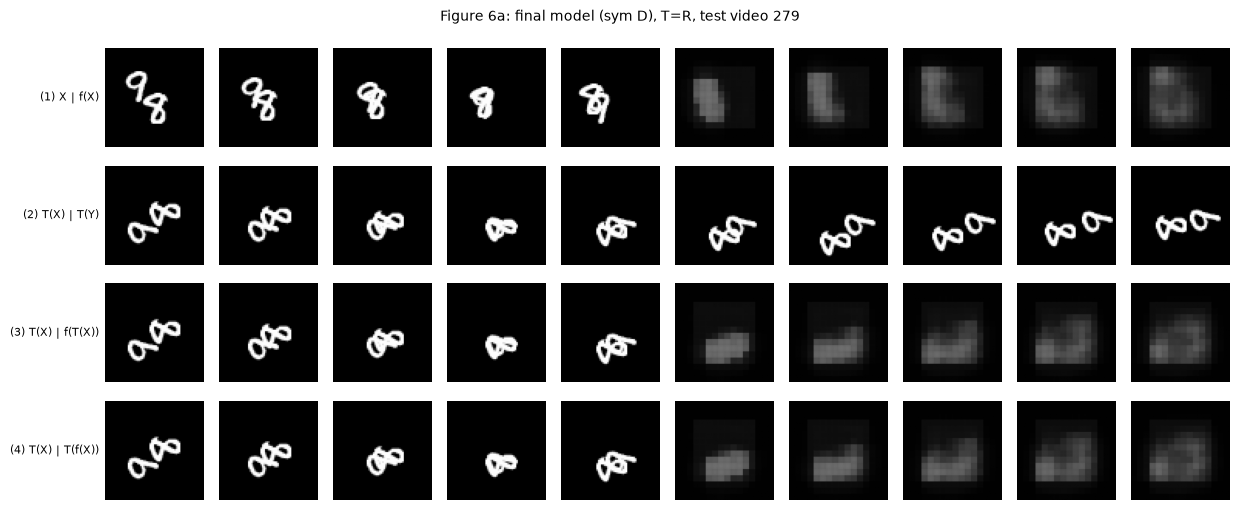

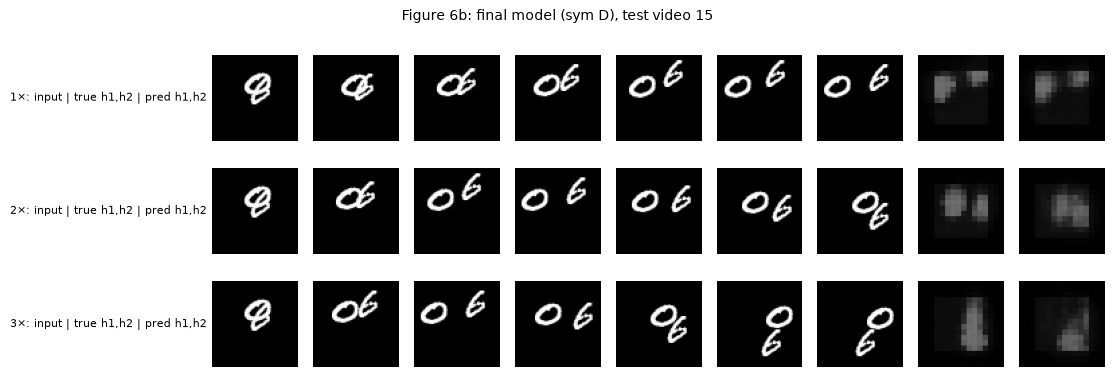

In [25]:
final = sym[FINAL][0]                                   # seed-0 final model

# (a) Figure 3 again, same videos
for c, tname in [("CM", "M"), ("CR", "R")]:
    for vid in fig3_idx[c]:
        rows = four_rows(final, test_videos[vid], TRANSFORMS[tname])
        show_grid(rows, labels4, f"Figure 6a: final model (sym {FINAL}), T={tname}, test video {vid}",
                  f"figures/figure6a_{tname}_test{vid}.png")
        save_gif(rows, f"gifs/figure6a_final_{tname}_test{vid}.gif")

# (b) Figure 5 again, same video
rows, labels = [], []
for k in [1, 2, 3]:
    P, Y, _ = predict(final, test_videos[fig5_vid:fig5_vid + 1], k=k)
    X, _, _ = make_window(test_videos[fig5_vid], 1, k)
    rows.append(list(to_float(X)) + list(Y[0, :2]) + list(P[0, :2]))
    labels.append(f"{k}×: input | true h1,h2 | pred h1,h2")
show_grid(rows, labels, f"Figure 6b: final model (sym {FINAL}), test video {fig5_vid}", "figures/figure6b.png")